# 02 — Baseline, Breakdown & Problem Detection

Phân tích mô tả để xác định vấn đề tiềm năng, không điều tra nguyên nhân. Không có target/benchmark business; đối chiếu nội bộ không chứng minh không đạt mục tiêu.

Absolute metrics là tổng record nguồn, có thể chứa bài lặp. Efficiency được mô tả bằng **mean/median rate nguồn ở cấp record**, không gọi là overall ER/CTR hoặc rate tính từ tổng. Chênh lệch rate dùng **điểm phần trăm (pp)**; không kiểm định ý nghĩa thống kê hay nhân quả. Click/CTR kèm số record được ghi nhận và chỉ áp dụng cho mẫu đó.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/Social_Media_Content_Performance_Dataset.xlsx").exists())
out = next(p for p in root.iterdir() if p.is_dir() and p.name.startswith("2."))
artifacts = out / "artifacts"
tables = artifacts / "tables"
figures = artifacts / "figures"
for folder in [artifacts, tables, figures]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
import matplotlib.pyplot as plt

df = pd.read_csv(artifacts / "analysis_ready.csv", parse_dates=["Post_Date", "Post_Published_At"])
counts = ["Engagement", "Views", "Likes", "Shares", "Comments", "Impressions",
          "Video_Views", "Live_Stream_Views", "Clicks"]
rates = ["Engagement_Rate", "Click_Through_Rate"]
data = df.copy()
for col in counts + rates:
    data.loc[data["Invalid_" + col], col] = np.nan  # KPI-specific mask only

def summarize(frame):
    return pd.Series({
        "records": len(frame), "unique_ids": frame.Post_ID.nunique(),
        "impressions_sum": frame.Impressions.sum(min_count=1),
        "views_sum": frame.Views.sum(min_count=1),
        "views_mean": frame.Views.mean(), "views_median": frame.Views.median(),
        "engagement_sum": frame.Engagement.sum(min_count=1),
        "engagement_mean": frame.Engagement.mean(), "engagement_median": frame.Engagement.median(),
        "er_records": frame.Engagement_Rate.count(),
        "er_mean_pct": frame.Engagement_Rate.mean()*100,
        "er_median_pct": frame.Engagement_Rate.median()*100,
        "click_records": frame.Clicks.count(), "click_coverage_pct": frame.Clicks.notna().mean()*100,
        "clicks_observed_sum": frame.Clicks.sum(min_count=1),
        "clicks_observed_mean": frame.Clicks.mean(),
        "ctr_records": frame.Click_Through_Rate.count(),
        "ctr_mean_pct": frame.Click_Through_Rate.mean()*100,
        "ctr_median_pct": frame.Click_Through_Rate.dropna().median()*100 if frame.Click_Through_Rate.notna().any() else np.nan})

def breakdown(column):
    result = pd.DataFrame({label: summarize(group) for label, group in data.groupby(column)}).T
    result["record_share_pct"] = result.records / len(data)*100
    result["views_share_pct"] = result.views_sum / data.Views.sum()*100
    result["engagement_share_pct"] = result.engagement_sum / data.Engagement.sum()*100
    result.index.name = column
    return result

baseline = summarize(data).to_frame("value")
display(baseline.round(4))
baseline.to_csv(tables / "baseline.csv", index_label="metric")


,value
records,5.600000e+03
unique_ids,5.000000e+03
impressions_sum,5.766556e+09
views_sum,4.806275e+09
views_mean,8.582634e+05
views_median,3.755250e+05
engagement_sum,6.464914e+08
engagement_mean,1.154449e+05
engagement_median,5.899150e+04
er_records,5.600000e+03


## Baseline theo thời gian

Tháng ở đây là cohort ngày xuất bản. Không biết các cohort được đo trong cùng cửa sổ performance hay không. Không diễn giải tổng giảm là suy giảm efficiency; đọc cùng số record và rate. Tháng partial giữ trong bảng, tách khỏi biểu đồ so sánh tháng trọn.


,records,partial_month,observed_posting_days,impressions_sum,views_sum,engagement_sum,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct
Month,,,,,,,,,,,,
2024-01,365.0,False,31,390130037.0,324864523.0,44548650.0,15.222,15.304,115.0,31.507,2145662.0,1.787
2024-02,297.0,False,29,336683950.0,279497122.0,37670906.0,15.127,15.125,98.0,32.997,2142201.0,1.763
2024-03,393.0,False,31,358618299.0,299059206.0,39230752.0,15.301,15.685,134.0,34.097,2011967.0,1.879
2024-04,353.0,False,30,327929790.0,273066884.0,34641091.0,14.658,14.630,118.0,33.428,1660046.0,1.832
2024-05,383.0,False,31,345400356.0,289509346.0,38187954.0,15.263,15.444,133.0,34.726,2333484.0,1.828
2024-06,365.0,False,30,381348633.0,316982825.0,41542295.0,15.361,15.373,104.0,28.493,1947934.0,1.865
2024-07,357.0,False,31,354247418.0,295613661.0,39627858.0,15.517,15.331,109.0,30.532,2343413.0,1.897
2024-08,350.0,False,31,379483732.0,317344761.0,39639195.0,15.171,15.401,122.0,34.857,2396636.0,1.796
2024-09,319.0,False,30,314212992.0,262617738.0,36838691.0,15.590,16.016,100.0,31.348,1876416.0,1.889


Full-month ER mean range: 14.658187353177873 15.67839132511986
Full-month CTR mean range: 1.7625510204081631 1.923706896551724
End-minus-start mean source ER (pp): 0.4389700065815543


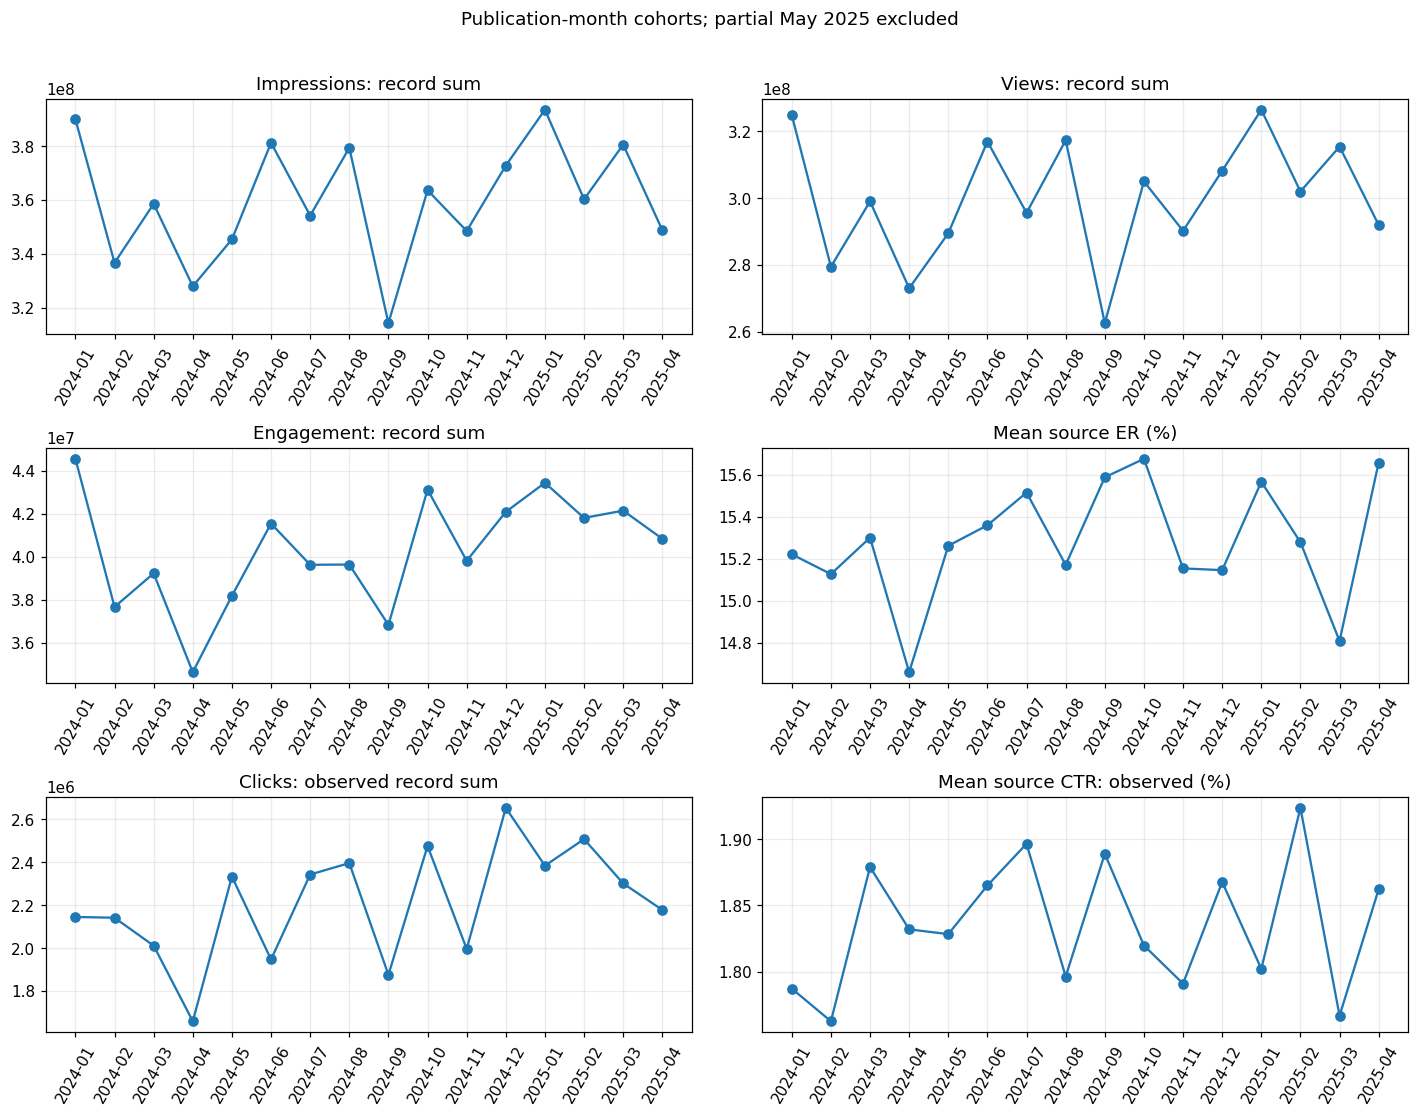

In [2]:
monthly = breakdown("Month")
monthly["partial_month"] = data.groupby("Month").Partial_Month.any()
monthly["observed_posting_days"] = data.groupby("Month").Post_Date.nunique()
monthly.to_csv(tables / "monthly.csv")
display(monthly[["records", "partial_month", "observed_posting_days", "impressions_sum", "views_sum",
                 "engagement_sum", "er_mean_pct", "er_median_pct", "click_records", "click_coverage_pct",
                 "clicks_observed_sum", "ctr_mean_pct"]].round(3))
full = monthly.loc[~monthly.partial_month]
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, col, label in zip(axes.flat,
    ["impressions_sum", "views_sum", "engagement_sum", "er_mean_pct", "clicks_observed_sum", "ctr_mean_pct"],
    ["Impressions: record sum", "Views: record sum", "Engagement: record sum", "Mean source ER (%)",
     "Clicks: observed record sum", "Mean source CTR: observed (%)"]):
    ax.plot(full.index, full[col], marker='o')
    ax.set_title(label)
    ax.tick_params(axis='x', rotation=60)
    ax.grid(alpha=.25)
fig.suptitle("Publication-month cohorts; partial May 2025 excluded", y=1.01)
fig.tight_layout()
fig.savefig(figures / "monthly_trends.png", dpi=150, bbox_inches="tight")
print("Full-month ER mean range:", full.er_mean_pct.min(), full.er_mean_pct.max())
print("Full-month CTR mean range:", full.ctr_mean_pct.min(), full.ctr_mean_pct.max())
print("End-minus-start mean source ER (pp):", full.er_mean_pct.iloc[-1]-full.er_mean_pct.iloc[0])


## Performance breakdown

Các bảng xuất đầy đủ KPI, volume, per-record mean/median và coverage cho mọi chiều. Mẫu nhỏ được đánh dấu khi n < 100; đây là ngưỡng sàng lọc thực hành, không phải ngưỡng ý nghĩa thống kê. Hashtag chỉ là hashtag chính, không phải toàn bộ tag của bài.


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Platform,,,,,,,,,,,,,,,
Facebook,299.0,3.186185e+08,2.653202e+08,35701985.0,5.520,887358.642,369247.0,5.522,15.290,15.330,299.0,100.000,6586141.0,2.042,False
Instagram,998.0,1.181864e+09,9.849258e+08,134738386.0,20.492,986899.550,368711.0,20.841,15.849,15.923,0.0,0.000,NaN,NaN,False
LinkedIn,525.0,4.084363e+08,3.405808e+08,44731424.0,7.086,648725.282,374865.0,6.919,14.329,14.105,304.0,57.905,5853029.0,1.974,False
TikTok,1257.0,1.307696e+09,1.087940e+09,146646344.0,22.636,865505.003,382281.0,22.683,15.341,15.423,1257.0,100.000,22968006.0,1.753,False
X.com,1201.0,1.197901e+09,9.996572e+08,133273396.0,20.799,832353.998,377084.0,20.615,15.284,15.460,0.0,0.000,NaN,NaN,False
YouTube,1320.0,1.352039e+09,1.127852e+09,151399907.0,23.466,854432.981,375668.5,23.419,15.180,15.412,0.0,0.000,NaN,NaN,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Content_Category,,,,,,,,,,,,,,,
Customer Story,735.0,4.391104e+08,3.665767e+08,72692576.0,7.627,498743.869,269383.0,11.244,19.876,19.892,296.0,40.272,3195410.0,1.857,False
Educational,2026.0,1.433752e+09,1.197011e+09,238044553.0,24.905,590824.918,285002.0,36.821,19.887,19.743,618.0,30.503,8340815.0,1.811,False
Entertainment,877.0,1.317365e+09,1.096495e+09,81828776.0,22.814,1250279.834,767331.0,12.657,7.512,7.514,285.0,32.497,7917350.0,1.853,False
Event / Webinar,577.0,2.615075e+08,2.178063e+08,30586034.0,4.532,377480.640,267567.0,4.731,13.943,14.078,180.0,31.196,1641757.0,1.845,False
Product Promotion,1385.0,2.314821e+09,1.928385e+09,223339503.0,40.122,1392336.075,1424464.0,34.546,11.593,11.593,481.0,34.729,14311844.0,1.841,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Post_Type,,,,,,,,,,,,,,,
Article,207.0,2.267317e+08,1.894920e+08,25415618.0,3.943,915420.232,414267.0,3.931,15.124,15.593,207.0,100.000,4627854.0,1.977,False
Carousel,51.0,5.098720e+07,4.231862e+07,5666210.0,0.880,829776.804,430378.0,0.876,14.509,16.250,25.0,49.020,645316.0,1.994,True
Image,996.0,4.290322e+08,3.577585e+08,58601693.0,7.444,359195.232,272708.5,9.065,17.857,18.341,74.0,7.430,2168618.0,2.124,False
Live Stream,924.0,4.206273e+08,3.497518e+08,52172995.0,7.277,378519.276,263112.0,8.070,14.965,14.447,386.0,41.775,2999328.0,1.819,False
PDF,16.0,1.447257e+07,1.207118e+07,1880729.0,0.251,754448.938,288737.0,0.291,17.619,17.723,4.0,25.000,30404.0,1.702,True
Text,458.0,2.560110e+08,2.137415e+08,30595341.0,4.447,466684.493,311373.5,4.733,15.948,16.581,87.0,18.996,1975301.0,1.964,False
Video,2948.0,4.368694e+09,3.641142e+09,472158856.0,75.758,1235122.689,913870.5,73.034,14.423,14.104,1077.0,36.533,22960355.0,1.781,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Content_Type,,,,,,,,,,,,,,,
Organic,4646.0,4.649611e+09,3.877399e+09,523553801.0,80.674,834567.159,365325.0,80.984,15.260,15.358,1415.0,30.456,25929464.0,1.831,False
Sponsored,954.0,1.116944e+09,9.288762e+08,122937641.0,19.326,973664.794,471713.0,19.016,15.399,15.817,445.0,46.646,9477712.0,1.852,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Region,,,,,,,,,,,,,,,
Australia,679.0,722396800.0,603736968.0,79365047.0,12.561,889156.065,366193.0,12.276,15.465,15.645,222.0,32.695,4631396.0,1.868,False
Brazil,718.0,720255718.0,600130929.0,82642904.0,12.486,835836.948,373660.0,12.783,15.437,15.566,238.0,33.148,4211038.0,1.803,False
Canada,735.0,718829640.0,598961591.0,80395116.0,12.462,814913.729,370070.0,12.436,15.313,15.590,236.0,32.109,4032099.0,1.816,False
Germany,627.0,641093252.0,536466408.0,71288254.0,11.162,855608.306,408850.0,11.027,14.631,14.583,206.0,32.855,3982883.0,1.905,False
India,691.0,677146005.0,562927944.0,77422582.0,11.712,814656.938,366523.0,11.976,15.419,15.613,220.0,31.838,4018921.0,1.870,False
Japan,666.0,745674763.0,624333976.0,82781768.0,12.990,937438.402,394176.0,12.805,15.067,15.291,249.0,37.387,5198818.0,1.815,False
UK,732.0,733408049.0,608971541.0,82036136.0,12.670,831928.335,357592.0,12.689,15.449,15.689,260.0,35.519,4800506.0,1.820,False
USA,752.0,807751517.0,670745877.0,90559635.0,13.956,891949.305,380353.5,14.008,15.396,15.510,229.0,30.452,4531515.0,1.803,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Post_Hour,,,,,,,,,,,,,,,
8,194.0,221811715.0,186311050.0,26497702.0,3.876,960366.237,431475.0,4.099,14.963,14.563,56.0,28.866,1224759.0,1.792,False
9,212.0,228627553.0,190835270.0,24047963.0,3.971,900166.368,399860.5,3.720,14.716,14.535,70.0,33.019,1349439.0,1.791,False
10,731.0,746704271.0,623941135.0,80775876.0,12.982,853544.644,380017.0,12.495,14.885,14.910,233.0,31.874,4648221.0,1.817,False
11,750.0,784498125.0,651205847.0,87854645.0,13.549,868274.463,379530.0,13.589,15.403,15.607,253.0,33.733,4745484.0,1.845,False
12,754.0,773298318.0,643827754.0,85236015.0,13.396,853882.963,356774.0,13.184,15.091,15.450,246.0,32.626,4786688.0,1.826,False
13,169.0,171196213.0,141743321.0,19011945.0,2.949,838717.876,408346.0,2.941,15.674,16.045,57.0,33.728,946785.0,1.750,False
14,167.0,157736009.0,131477623.0,17989079.0,2.736,787291.156,368398.0,2.783,15.590,15.927,62.0,37.126,1020662.0,1.856,False
15,758.0,758177673.0,634229994.0,85485277.0,13.196,836715.032,371417.5,13.223,15.257,15.440,268.0,35.356,4917644.0,1.834,False
16,766.0,779213087.0,650241564.0,89713337.0,13.529,848879.326,369393.5,13.877,15.606,15.627,251.0,32.768,4517220.0,1.881,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Weekday,,,,,,,,,,,,,,,
Friday,778.0,804127584.0,670191468.0,90286025.0,13.944,861428.622,382506.0,13.966,15.118,15.150,266.0,34.190,4918473.0,1.841,False
Monday,793.0,794828828.0,663106787.0,89769636.0,13.797,836200.236,354840.0,13.886,15.411,15.657,259.0,32.661,4665601.0,1.831,False
Saturday,799.0,864413272.0,721030937.0,97835985.0,15.002,902416.692,390861.0,15.133,15.166,15.216,267.0,33.417,5789127.0,1.835,False
Sunday,774.0,792449325.0,661578965.0,90775992.0,13.765,854753.185,374404.5,14.041,15.443,15.672,251.0,32.429,5031832.0,1.853,False
Thursday,825.0,809253006.0,673800186.0,89961582.0,14.019,816727.498,357091.0,13.915,15.320,15.449,295.0,35.758,4966602.0,1.805,False
Tuesday,785.0,794639877.0,663194069.0,87456626.0,13.799,844833.209,382281.0,13.528,15.333,15.712,246.0,31.338,4847895.0,1.842,False
Wednesday,846.0,906843852.0,753372822.0,100405596.0,15.675,890511.610,387203.0,15.531,15.201,15.169,276.0,32.624,5187646.0,1.846,False


,records,impressions_sum,views_sum,engagement_sum,views_share_pct,views_mean,views_median,engagement_share_pct,er_mean_pct,er_median_pct,click_records,click_coverage_pct,clicks_observed_sum,ctr_mean_pct,small_sample
Main_Hashtag,,,,,,,,,,,,,,,
#BehindTheScenes,4.0,1.454062e+06,1.224881e+06,176561.0,0.025,306220.250,276193.5,0.027,14.280,14.752,4.0,100.000,30554.0,1.985,True
#CaseStudy2025,1.0,9.304900e+04,7.735800e+04,20832.0,0.002,77358.000,77358.0,0.003,26.930,26.930,1.0,100.000,1944.0,2.090,True
#CustomerStory,1005.0,1.212706e+09,1.012989e+09,200993640.0,21.076,1007949.166,389066.0,31.090,19.760,19.710,160.0,15.920,5460281.0,1.907,False
#CustomerSuccess,92.0,5.239601e+07,4.370616e+07,8590980.0,0.909,475066.935,252185.5,1.329,19.713,19.718,92.0,100.000,1033484.0,1.873,True
#DidYouKnow,124.0,1.136457e+08,9.456124e+07,12713902.0,1.967,762590.669,362550.0,1.967,15.235,16.597,92.0,74.194,1916929.0,1.970,False
#EventRecap,365.0,1.213051e+08,1.011098e+08,14186714.0,2.104,277013.077,256770.0,2.194,14.009,14.248,120.0,32.877,688336.0,1.777,False
#EventSummary,38.0,1.828786e+07,1.506489e+07,2061409.0,0.313,396444.474,281074.5,0.319,13.977,13.395,38.0,100.000,359325.0,2.012,True
#FeatureHighlight,354.0,1.982901e+08,1.648179e+08,19004513.0,3.429,465587.271,347918.0,2.940,11.459,11.319,142.0,40.113,1857226.0,1.794,False
#FunContent,299.0,1.920086e+08,1.609064e+08,12285545.0,3.348,538148.375,523294.0,1.900,7.572,7.625,118.0,39.465,1467467.0,1.781,False


Platform
Content_Category
Post_Type
Content_Type
Region
Post_Hour
Weekday
Main_Hashtag


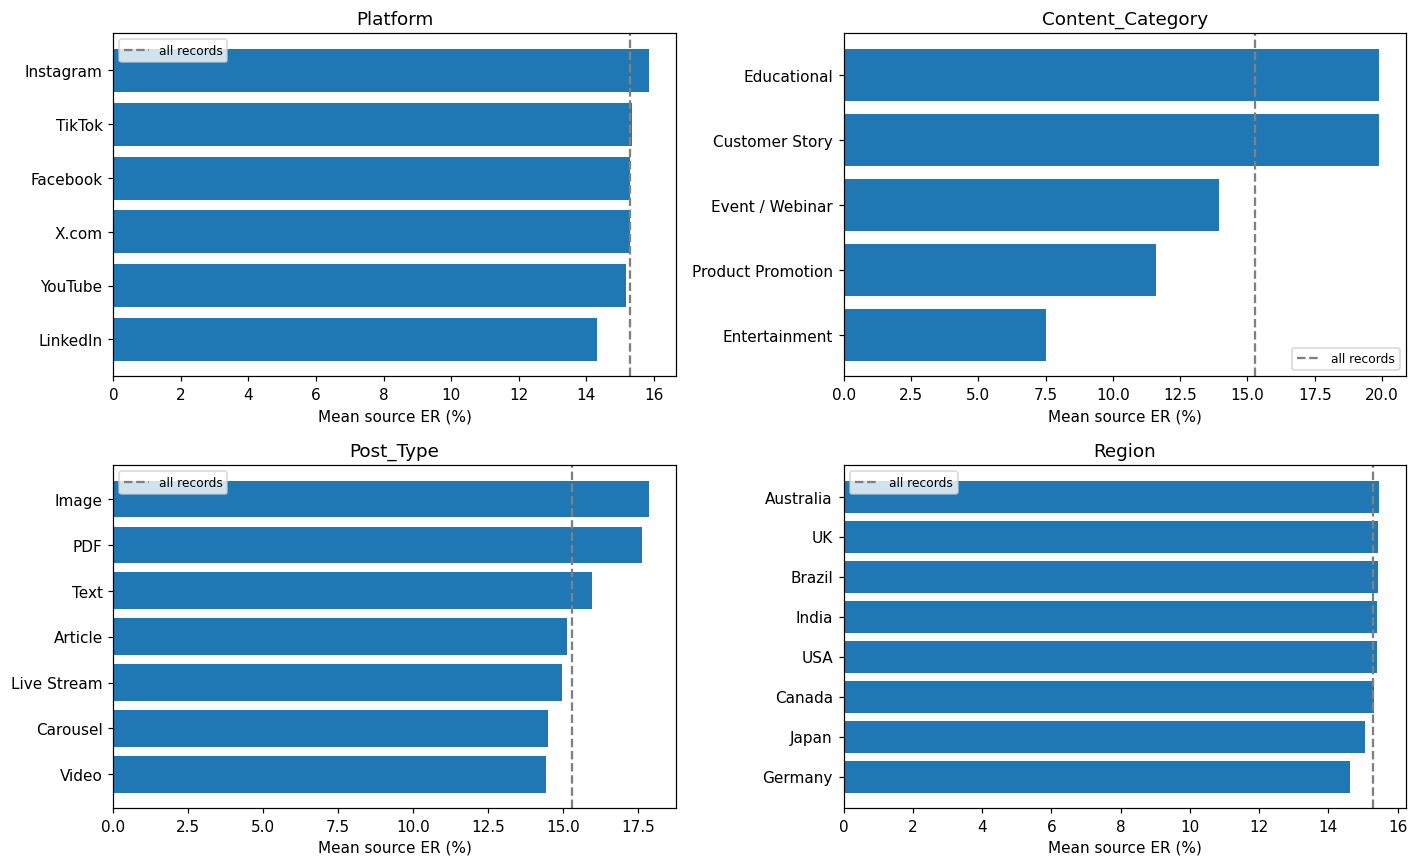

In [3]:
segments = {}
for column in ["Platform", "Content_Category", "Post_Type", "Content_Type", "Region",
               "Post_Hour", "Weekday", "Main_Hashtag"]:
    table = breakdown(column)
    table["small_sample"] = table.records < 100
    segments[column] = table
    table.to_csv(tables / ("by_" + column.lower() + ".csv"))
    print(column)
    display(table[["records", "impressions_sum", "views_sum", "engagement_sum", "views_share_pct", "views_mean", "views_median", "engagement_share_pct",
                   "er_mean_pct", "er_median_pct", "click_records", "click_coverage_pct",
                   "clicks_observed_sum", "ctr_mean_pct", "small_sample"]].round(3))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, dimension in zip(axes.flat, ["Platform", "Content_Category", "Post_Type", "Region"]):
    t = segments[dimension].sort_values("er_mean_pct")
    ax.barh(t.index.astype(str), t.er_mean_pct)
    ax.axvline(data.Engagement_Rate.mean()*100, color='gray', linestyle='--', label='all records')
    ax.set_xlabel("Mean source ER (%)")
    ax.set_title(dimension)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "segment_er_comparison.png", dpi=150, bbox_inches="tight")


## Candidate evidence và kiểm tra độ nhạy

So category với phần còn lại để tránh baseline chứa chính segment. Đối chiếu category khác mục đích chỉ là tín hiệu cần điều tra: không có mục tiêu riêng để gọi nhóm này thất bại.

Kiểm tra độ nhạy gồm: median, chỉ tháng trọn và giảm trọng số mã bài lặp. Mỗi Post_ID nhận tổng trọng số 1 trong phép kiểm tra rate; không gom/xóa record hoặc chọn category đại diện. Kiểm tra này không giải quyết grain và không chứng minh khoảng cách đã điều chỉnh các yếu tố khác.


,records,views_share_pct,engagement_share_pct,er_mean_pct,rest_er_mean_pct,gap_pp,relative_gap_pct,er_median_pct,rest_er_median_pct,full_month_er_pct,full_month_rest_er_pct,id_weighted_er_pct,id_weighted_rest_er_pct
category,,,,,,,,,,,,,
Entertainment,877,22.8138,12.6574,7.5119,16.7268,9.2149,55.0908,7.5137,16.6550,7.5111,16.7236,7.5146,16.7324
Product Promotion,1385,40.1222,34.5464,11.5928,16.4965,4.9037,29.7256,11.5934,17.4024,11.5943,16.4915,11.5839,16.4926


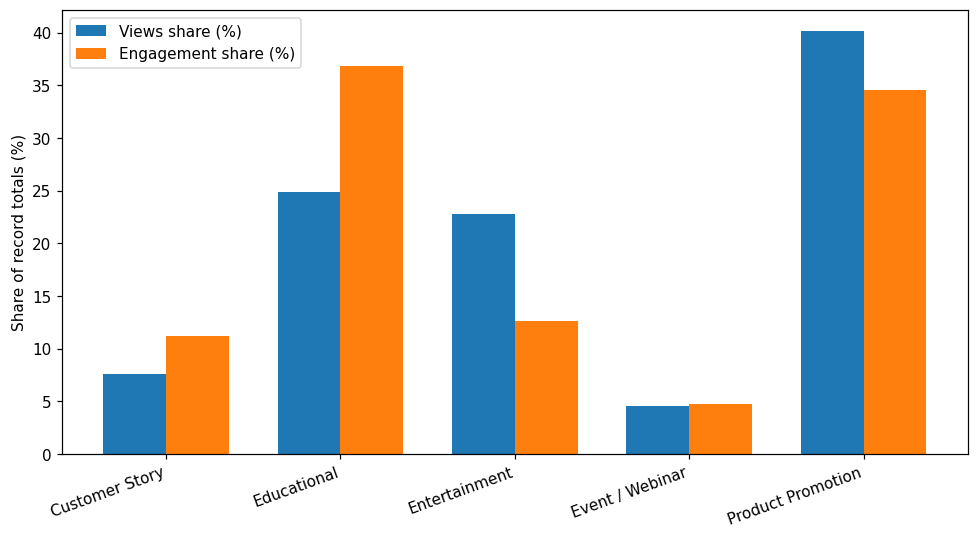

In [4]:
evidence = []
id_weights = 1 / data.groupby("Post_ID").Post_ID.transform("size")
for category in ["Entertainment", "Product Promotion"]:
    mask = data.Content_Category.eq(category)
    a, b = data.loc[mask], data.loc[~mask]
    a_full = a.loc[~a.Partial_Month]; b_full = b.loc[~b.Partial_Month]
    weighted_a = np.average(a.Engagement_Rate, weights=id_weights.loc[mask])*100
    weighted_b = np.average(b.Engagement_Rate, weights=id_weights.loc[~mask])*100
    evidence.append({"category": category, "records": len(a),
        "views_share_pct": a.Views.sum()/data.Views.sum()*100,
        "engagement_share_pct": a.Engagement.sum()/data.Engagement.sum()*100,
        "er_mean_pct": a.Engagement_Rate.mean()*100,
        "rest_er_mean_pct": b.Engagement_Rate.mean()*100,
        "gap_pp": (b.Engagement_Rate.mean()-a.Engagement_Rate.mean())*100,
        "relative_gap_pct": (1-a.Engagement_Rate.mean()/b.Engagement_Rate.mean())*100,
        "er_median_pct": a.Engagement_Rate.median()*100,
        "rest_er_median_pct": b.Engagement_Rate.median()*100,
        "full_month_er_pct": a_full.Engagement_Rate.mean()*100,
        "full_month_rest_er_pct": b_full.Engagement_Rate.mean()*100,
        "id_weighted_er_pct": weighted_a, "id_weighted_rest_er_pct": weighted_b})
evidence = pd.DataFrame(evidence).set_index("category")
display(evidence.round(4))
evidence.to_csv(tables / "category_candidate_evidence.csv")
fig, ax = plt.subplots(figsize=(9, 5))
cat = segments['Content_Category']
x = np.arange(len(cat))
ax.bar(x-.18, cat.views_share_pct, width=.36, label='Views share (%)')
ax.bar(x+.18, cat.engagement_share_pct, width=.36, label='Engagement share (%)')
ax.set_xticks(x, cat.index, rotation=20, ha='right')
ax.set_ylabel("Share of record totals (%)")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "category_volume_shares.png", dpi=150, bbox_inches="tight")


In [5]:
ent_months = pd.DataFrame({m: pd.Series({
    "ent_records": len(g.loc[g.Content_Category.eq("Entertainment")]),
    "ent_er_pct": g.loc[g.Content_Category.eq("Entertainment"), "Engagement_Rate"].mean()*100,
    "rest_er_pct": g.loc[~g.Content_Category.eq("Entertainment"), "Engagement_Rate"].mean()*100})
    for m, g in data.loc[~data.Partial_Month].groupby("Month")}).T
ent_months["gap_pp"] = ent_months.rest_er_pct - ent_months.ent_er_pct
display(ent_months.round(3))
ent_months.to_csv(tables / "entertainment_monthly_evidence.csv", index_label="Month")
print("Months with Entertainment below rest:", int((ent_months.gap_pp > 0).sum()), "/", len(ent_months))
print("Minimum/maximum monthly gap pp:", ent_months.gap_pp.min(), ent_months.gap_pp.max())
print("No inference about the reasons for any gap is made.")


,ent_records,ent_er_pct,rest_er_pct,gap_pp
2024-01,63.0,7.729,16.785,9.056
2024-02,47.0,7.369,16.586,9.216
2024-03,66.0,7.449,16.886,9.437
2024-04,56.0,7.705,15.969,8.265
2024-05,69.0,7.500,16.969,9.469
2024-06,50.0,7.415,16.622,9.207
2024-07,46.0,7.499,16.703,9.204
2024-08,54.0,7.504,16.570,9.065
2024-09,41.0,7.457,16.789,9.333
2024-10,54.0,7.591,17.222,9.630


Months with Entertainment below rest: 16 / 16
Minimum/maximum monthly gap pp: 8.264710170806776 9.827007037434857
No inference about the reasons for any gap is made.
